## Setting Up

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from google.colab import drive
# from gensim.models import Word2Vec
from scipy.sparse import csr_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# Mount Google Drive
drive.mount('/content/drive')

# Read csv file from a directory into pandas DataFrame
df_behaviors_train = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/ebnerd_large/train/behaviors.parquet")
df_history_train = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/ebnerd_large/train/history.parquet")
df_articles = pd.read_parquet("/content/drive/MyDrive/Colab Notebooks/ebnerd_large/articles.parquet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_behaviors_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12063890 entries, 0 to 12063889
Data columns (total 17 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   impression_id           uint32        
 1   article_id              float64       
 2   impression_time         datetime64[us]
 3   read_time               float32       
 4   scroll_percentage       float32       
 5   device_type             int8          
 6   article_ids_inview      object        
 7   article_ids_clicked     object        
 8   user_id                 uint32        
 9   is_sso_user             bool          
 10  gender                  float64       
 11  postcode                float64       
 12  age                     float64       
 13  is_subscriber           bool          
 14  session_id              uint32        
 15  next_read_time          float32       
 16  next_scroll_percentage  float32       
dtypes: bool(2), datetime64[us](1), float32(4), f

In [ ]:
df_history_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 788090 entries, 0 to 788089
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   user_id                  788090 non-null  uint32
 1   impression_time_fixed    788090 non-null  object
 2   scroll_percentage_fixed  788090 non-null  object
 3   article_id_fixed         788090 non-null  object
 4   read_time_fixed          788090 non-null  object
dtypes: object(4), uint32(1)
memory usage: 27.1+ MB


In [ ]:
df_articles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125541 entries, 0 to 125540
Data columns (total 21 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   article_id          125541 non-null  int32         
 1   title               125541 non-null  object        
 2   subtitle            125541 non-null  object        
 3   last_modified_time  125541 non-null  datetime64[us]
 4   premium             125541 non-null  bool          
 5   body                125541 non-null  object        
 6   published_time      125541 non-null  datetime64[us]
 7   image_ids           111219 non-null  object        
 8   article_type        125541 non-null  object        
 9   url                 125541 non-null  object        
 10  ner_clusters        125541 non-null  object        
 11  entity_groups       125541 non-null  object        
 12  topics              125541 non-null  object        
 13  category            125541 no

## Analysis on Current Features - User Related
- Analyse `age`, `gender`, `is_subscriber`, `postcode`
- These describe the user profile

In [3]:
# Create working copy
beh = df_behaviors_train.copy()

# Number of candidate articles shown in each impression
beh["n_exposures"] = (
    beh["article_ids_inview"]
    .apply(len)
)

# Number of candidate articles clicked in each impression
beh["n_clicks"] = (
    beh["article_ids_clicked"]
    .apply(len)
)

In [ ]:
user_fields = [
    "gender",
    "age",
    "is_subscriber",
    "postcode"
]

# One row per unique user
user_df = (
    df_behaviors_train[
        ["user_id"] + user_fields
    ]
    .drop_duplicates("user_id")
)

for col in user_fields:
    print(f"\n===== {col} =====")

    # Missingness
    missing_pct = (
        user_df[col]
        .isna()
        .mean()
        * 100
    )

    print(
        f"Missing: {missing_pct:.2f}%"
    )

    # Number of unique non-null values
    print(
        "Unique values:",
        user_df[col].nunique(
            dropna=True
        )
    )

    # Distribution
    print(
        user_df[col]
        .value_counts(
            dropna=False,
            normalize=True
        )
        .mul(100)
        .head(20)
    )


===== gender =====
Missing: 95.73%
Unique values: 3
gender
NaN    95.729168
0.0     3.624586
1.0     0.646119
2.0     0.000127
Name: proportion, dtype: float64

===== age =====
Missing: 98.12%
Unique values: 11
age
NaN      98.116713
50.0      0.491314
60.0      0.421272
40.0      0.348184
70.0      0.269132
30.0      0.223959
20.0      0.067378
80.0      0.049233
0.0       0.007740
90.0      0.002918
10.0      0.002030
100.0     0.000127
Name: proportion, dtype: float64

===== is_subscriber =====
Missing: 0.00%
Unique values: 2
is_subscriber
False    96.744154
True      3.255846
Name: proportion, dtype: float64

===== postcode =====
Missing: 98.61%
Unique values: 5
postcode
NaN    98.608661
0.0     0.543847
3.0     0.273573
2.0     0.209113
1.0     0.204164
4.0     0.160642
Name: proportion, dtype: float64


In [ ]:
binary_cols = [
    "is_subscriber",
]

# One row per user
user_binary = (
    df_behaviors_train[
        ["user_id"] + binary_cols
    ]
    .drop_duplicates("user_id")
)

for col in binary_cols:
    print(f"\n===== {col} =====")

    dist = (
        user_binary[col]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .mul(100)
    )

    print(dist)


===== is_subscriber =====
is_subscriber
False    96.744154
True      3.255846
Name: proportion, dtype: float64


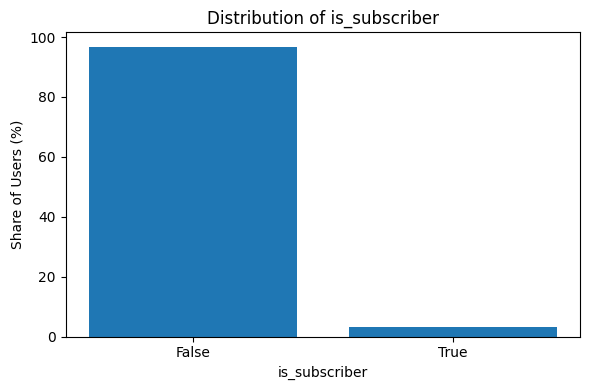

In [ ]:
for col in binary_cols:
    dist = (
        user_binary[col]
        .value_counts(normalize=True)
        .mul(100)
        .reset_index()
    )

    dist.columns = [
        col,
        "user_share_pct"
    ]

    plt.figure(figsize=(6, 4))

    plt.bar(
        dist[col].astype(str),
        dist["user_share_pct"]
    )

    plt.xlabel(col)
    plt.ylabel("Share of Users (%)")
    plt.title(
        f"Distribution of {col}"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
for col in binary_cols:
    ctr_table = (
        beh.groupby(col)
        .agg(
            exposures=(
                "n_exposures",
                "sum"
            ),
            clicks=(
                "n_clicks",
                "sum"
            )
        )
        .reset_index()
    )

    ctr_table["candidate_ctr"] = (
        ctr_table["clicks"]
        / ctr_table["exposures"]
    )

    print(f"\n===== {col} CTR =====")
    print(ctr_table)


===== is_subscriber CTR =====
   is_subscriber  exposures    clicks  candidate_ctr
0          False  124513451  11317230       0.090892
1           True    9297190    817005       0.087877


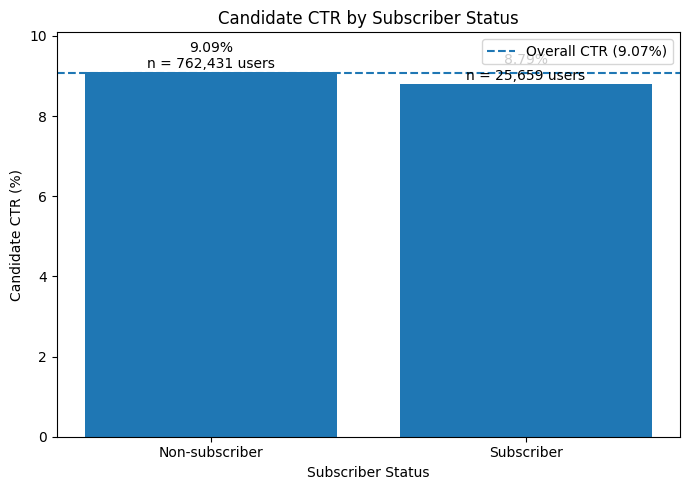

In [ ]:
overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)

# CTR by subscriber status
subscriber_ctr = (
    beh.groupby("is_subscriber")
    .agg(
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
    .reset_index()
)

subscriber_ctr["candidate_ctr"] = (
    subscriber_ctr["clicks"]
    / subscriber_ctr["exposures"]
)

# Unique user count by subscriber status
subscriber_users = (
    beh.groupby("is_subscriber")["user_id"]
    .nunique()
    .reset_index(name="user_count")
)

# Merge CTR and user counts
plot_df = subscriber_ctr.merge(
    subscriber_users,
    on="is_subscriber"
)

plot_df["status"] = (
    plot_df["is_subscriber"]
    .map({
        False: "Non-subscriber",
        True: "Subscriber"
    })
)

plot_df["ctr_pct"] = (
    plot_df["candidate_ctr"]
    * 100
)

# Plot
plt.figure(figsize=(7, 5))

bars = plt.bar(
    plot_df["status"],
    plot_df["ctr_pct"]
)

# Overall CTR reference line
plt.axhline(
    overall_ctr * 100,
    linestyle="--",
    label=f"Overall CTR ({overall_ctr * 100:.2f}%)"
)

# Add CTR + user count labels
for bar, (_, row) in zip(
    bars,
    plot_df.iterrows()
):
    height = bar.get_height()

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.03,
        (
            f"{row['ctr_pct']:.2f}%\n"
            f"n = {row['user_count']:,} users"
        ),
        ha="center",
        va="bottom"
    )

plt.xlabel("Subscriber Status")
plt.ylabel("Candidate CTR (%)")
plt.title(
    "Candidate CTR by Subscriber Status"
)

plt.legend()

# Give space for labels above bars
plt.ylim(
    0,
    plot_df["ctr_pct"].max() + 1
)

plt.tight_layout()
plt.show()

Findings
1. Age, Gender, Postcode have very limited coverage, with 98.12%, 95.73% and 98.61% of observations missing respectively. As a result, age-based, gender-based, postcode-based descriptive statistics and CTR comparisons would only reflect a small subset of users and may not be representative of the overall population. We therefore do not rely on age, gender, postcode as a primary model feature.
2. Subscriber status has complete coverage and is therefore retained for further analysis. Non-subscribers account for 96.74% of users, while subscribers account for only 3.26%, indicating a substantial class imbalance in this feature. Candidate CTR is slightly higher among non-subscribers at approximately 9.09%, compared with 8.79% among subscribers. The difference is relatively small, suggesting that subscriber status may have limited standalone predictive power. However, it is retained as a binary feature because it is fully observed and may provide additional value when combined with article-level features such as premium status.

## Analysis on Current Features - Impression / Context Related
- Analyse `device_type`, `impression_time`, `is_sso_user`, front-page vs article-page, derived from `article_id.isna()`
- These describe the situation in which the recommendation was shown.

In [ ]:
# Create working copy
beh = df_behaviors_train.copy()

# Helper columns for candidate-level CTR
beh["n_exposures"] = (
    beh["article_ids_inview"]
    .apply(len)
)

beh["n_clicks"] = (
    beh["article_ids_clicked"]
    .apply(len)
)

# Derived context features
beh["is_front_page"] = (
    beh["article_id"]
    .isna()
)

beh["hour"] = (
    beh["impression_time"]
    .dt.hour
)

beh["day_of_week"] = (
    beh["impression_time"]
    .dt.dayofweek
)

weekday_map = {
    0: "Mon",
    1: "Tue",
    2: "Wed",
    3: "Thu",
    4: "Fri",
    5: "Sat",
    6: "Sun"
}

beh["weekday"] = (
    beh["day_of_week"]
    .map(weekday_map)
)


# =========================
# Distribution checks
# =========================

print("===== device_type =====")
print(
    beh["device_type"]
    .value_counts(
        dropna=False,
        normalize=True
    )
    .mul(100)
)

print(
    f"Missing: "
    f"{beh['device_type'].isna().mean() * 100:.2f}%"
)


print("\n===== is_sso_user =====")
print(
    beh["is_sso_user"]
    .value_counts(
        dropna=False,
        normalize=True
    )
    .mul(100)
)

print(
    f"Missing: "
    f"{beh['is_sso_user'].isna().mean() * 100:.2f}%"
)


print("\n===== page context =====")

page_dist = (
    beh["is_front_page"]
    .map({
        True: "Front page",
        False: "Article page"
    })
    .value_counts(
        normalize=True
    )
    .mul(100)
)

print(page_dist)


print("\n===== hour of day =====")
print(
    beh["hour"]
    .value_counts(
        normalize=True
    )
    .sort_index()
    .mul(100)
)


print("\n===== day of week =====")
print(
    beh["weekday"]
    .value_counts(
        normalize=True
    )
    .reindex([
        "Mon",
        "Tue",
        "Wed",
        "Thu",
        "Fri",
        "Sat",
        "Sun"
    ])
    .mul(100)
)

===== device_type =====
device_type
2    62.948692
1    34.042403
3     3.005614
0     0.003291
Name: proportion, dtype: float64
Missing: 0.00%

===== is_sso_user =====
is_sso_user
False    89.452183
True     10.547817
Name: proportion, dtype: float64
Missing: 0.00%

===== page context =====
is_front_page
Front page      70.11028
Article page    29.88972
Name: proportion, dtype: float64

===== hour of day =====
hour
0     0.592437
1     0.595861
2     1.041754
3     2.813214
4     5.238708
5     6.581227
6     6.803295
7     6.305271
8     4.701842
9     4.351921
10    4.559168
11    4.167163
12    4.579808
13    4.661523
14    4.955781
15    5.062612
16    4.740113
17    5.300479
18    5.599388
19    5.744134
20    5.384797
21    3.556133
22    1.798839
23    0.864530
Name: proportion, dtype: float64

===== day of week =====
weekday
Mon    14.992991
Tue    13.877149
Wed    13.805613
Thu    15.132723
Fri    15.731899
Sat    12.832345
Sun    13.627279
Name: proportion, dtype: float64


In [ ]:
# Overall CTR
overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)

# Features to compare against CTR
context_features = [
    "device_type",
    "is_sso_user",
    "is_front_page",
    "hour",
    "weekday"
]

ctr_results = {}

for col in context_features:
    ctr_table = (
        beh.groupby(
            col,
            observed=True
        )
        .agg(
            impressions=(
                "impression_id",
                "size"
            ),
            exposures=(
                "n_exposures",
                "sum"
            ),
            clicks=(
                "n_clicks",
                "sum"
            )
        )
        .reset_index()
    )

    ctr_table["candidate_ctr"] = (
        ctr_table["clicks"]
        / ctr_table["exposures"]
    )

    ctr_results[col] = ctr_table

    print(f"\n===== {col} CTR =====")
    print(ctr_table)

print(
    f"\nOverall CTR: "
    f"{overall_ctr * 100:.2f}%"
)


===== device_type CTR =====
   device_type  impressions  exposures   clicks  candidate_ctr
0            0          397       4979      397       0.079735
1            1      4106838   48323948  4142132       0.085716
2            2      7594061   80899823  7627854       0.094288
3            3       362594    4581891   363852       0.079411

===== is_sso_user CTR =====
   is_sso_user  impressions  exposures    clicks  candidate_ctr
0        False     10791413  119353663  10854316       0.090942
1         True      1272477   14456978   1279919       0.088533

===== is_front_page CTR =====
   is_front_page  impressions  exposures   clicks  candidate_ctr
0          False      3605863   41575502  3614971       0.086950
1           True      8458027   92235139  8519264       0.092365

===== hour CTR =====
    hour  impressions  exposures  clicks  candidate_ctr
0      0        71471     820648   71811       0.087505
1      1        71884     828823   72203       0.087115
2      2       1256

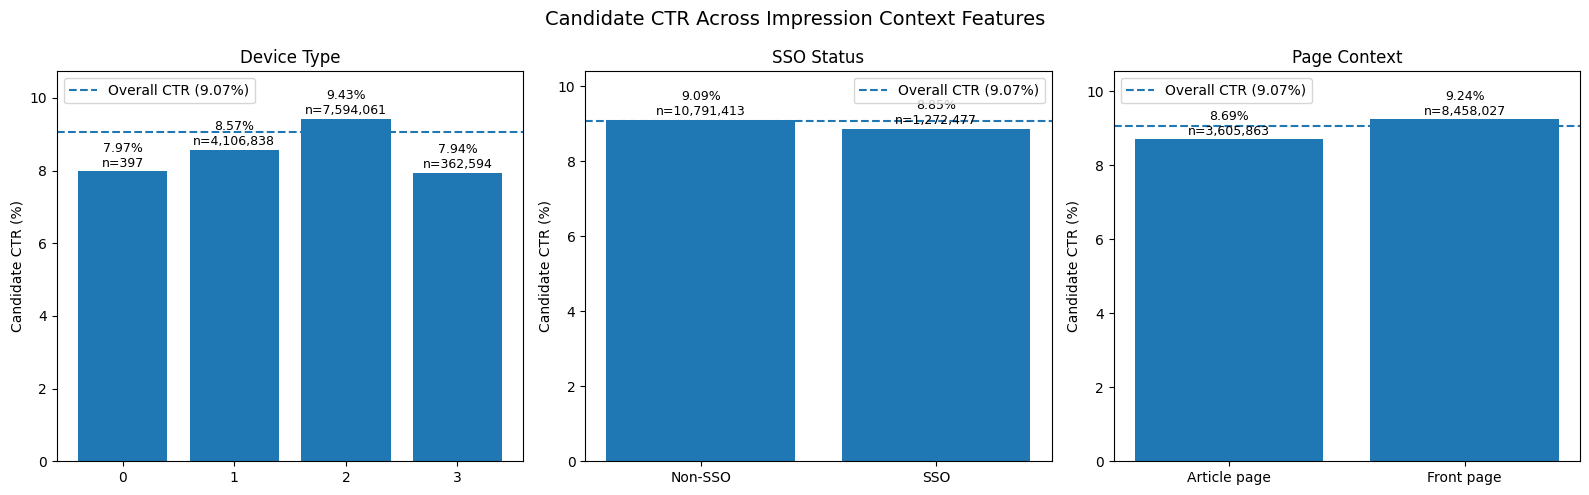

In [ ]:
# Overall candidate CTR
overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)

# Build CTR tables
features = [
    "device_type",
    "is_sso_user",
    "is_front_page"
]

ctr_results = {}

for col in features:
    table = (
        beh.groupby(col)
        .agg(
            impressions=(
                "impression_id",
                "size"
            ),
            exposures=(
                "n_exposures",
                "sum"
            ),
            clicks=(
                "n_clicks",
                "sum"
            )
        )
        .reset_index()
    )

    table["candidate_ctr"] = (
        table["clicks"]
        / table["exposures"]
    )

    ctr_results[col] = table


# -------------------------
# Plot all 3 together
# -------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

plot_info = [
    (
        "device_type",
        "Device Type",
        None
    ),
    (
        "is_sso_user",
        "SSO Status",
        {
            False: "Non-SSO",
            True: "SSO"
        }
    ),
    (
        "is_front_page",
        "Page Context",
        {
            False: "Article page",
            True: "Front page"
        }
    )
]

for ax, (col, title, label_map) in zip(
    axes,
    plot_info
):
    df = ctr_results[col].copy()

    # Create readable x labels
    if label_map is not None:
        df["label"] = (
            df[col]
            .map(label_map)
        )
    else:
        df["label"] = (
            df[col]
            .astype(str)
        )

    # CTR in percentage points
    df["ctr_pct"] = (
        df["candidate_ctr"]
        * 100
    )

    bars = ax.bar(
        df["label"],
        df["ctr_pct"]
    )

    # Overall CTR reference
    ax.axhline(
        overall_ctr * 100,
        linestyle="--",
        label=(
            f"Overall CTR "
            f"({overall_ctr * 100:.2f}%)"
        )
    )

    # Annotate each bar
    for bar, (_, row) in zip(
        bars,
        df.iterrows()
    ):
        height = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            height + 0.05,
            (
                f"{row['ctr_pct']:.2f}%\n"
                f"n={row['impressions']:,}"
            ),
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(
        "Candidate CTR (%)"
    )

    ax.legend()

    # Give enough room for labels
    ax.set_ylim(
        0,
        df["ctr_pct"].max() + 1.3
    )

plt.suptitle(
    "Candidate CTR Across Impression Context Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

===== CTR by Hour =====
    hour  impressions  exposures  clicks  candidate_ctr
0      0        71471     820648   71811       0.087505
1      1        71884     828823   72203       0.087115
2      2       125676    1407273  126237       0.089703
3      3       339383    3759892  340974       0.090687
4      4       631992    7032227  634792       0.090269
5      5       793952    8970736  798083       0.088965
6      6       820742    9330230  825667       0.088494
7      7       760661    8535580  765143       0.089642
8      8       567225    6296797  570764       0.090644
9      9       525011    5850476  528373       0.090313
10    10       550013    6031551  554034       0.091856
11    11       502722    5465958  506544       0.092673
12    12       552503    5834864  556533       0.095381
13    13       562361    6018709  566328       0.094095
14    14       597860    6587016  601760       0.091355
15    15       610748    6650430  614464       0.092395
16    16       571842   

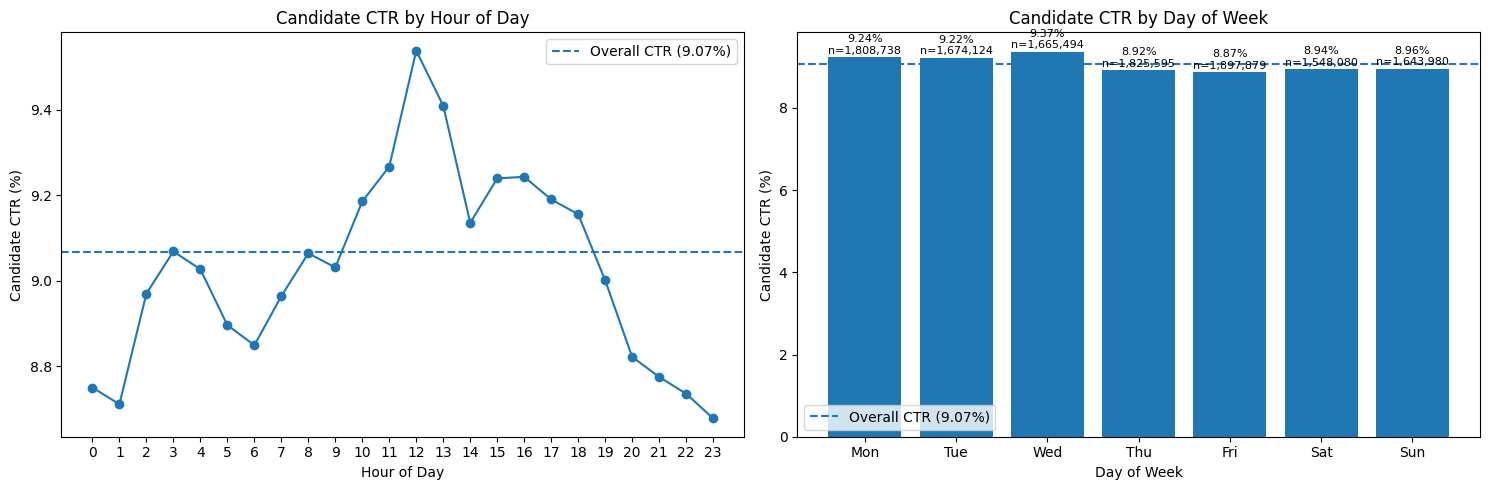

In [ ]:
# -------------------------
# Derive time features
# -------------------------

beh["hour"] = (
    beh["impression_time"]
    .dt.hour
)

beh["day_of_week"] = (
    beh["impression_time"]
    .dt.dayofweek
)

weekday_map = {
    0: "Mon",
    1: "Tue",
    2: "Wed",
    3: "Thu",
    4: "Fri",
    5: "Sat",
    6: "Sun"
}

beh["weekday"] = (
    beh["day_of_week"]
    .map(weekday_map)
)


# -------------------------
# Overall CTR
# -------------------------

overall_ctr = (
    beh["n_clicks"].sum()
    / beh["n_exposures"].sum()
)


# -------------------------
# CTR by hour
# -------------------------

hour_ctr = (
    beh.groupby("hour")
    .agg(
        impressions=(
            "impression_id",
            "size"
        ),
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
    .reset_index()
)

hour_ctr["candidate_ctr"] = (
    hour_ctr["clicks"]
    / hour_ctr["exposures"]
)


# -------------------------
# CTR by weekday
# -------------------------

weekday_order = [
    "Mon",
    "Tue",
    "Wed",
    "Thu",
    "Fri",
    "Sat",
    "Sun"
]

weekday_ctr = (
    beh.groupby(
        "weekday",
        observed=True
    )
    .agg(
        impressions=(
            "impression_id",
            "size"
        ),
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
    .reset_index()
)

weekday_ctr["candidate_ctr"] = (
    weekday_ctr["clicks"]
    / weekday_ctr["exposures"]
)

weekday_ctr["weekday"] = pd.Categorical(
    weekday_ctr["weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_ctr = (
    weekday_ctr
    .sort_values("weekday")
)


# -------------------------
# Print descriptive tables
# -------------------------

print("===== CTR by Hour =====")
print(hour_ctr)

print("\n===== CTR by Weekday =====")
print(weekday_ctr)


# -------------------------
# Plot
# -------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# Hour-of-day CTR
axes[0].plot(
    hour_ctr["hour"],
    hour_ctr["candidate_ctr"] * 100,
    marker="o"
)

axes[0].axhline(
    overall_ctr * 100,
    linestyle="--",
    label=(
        f"Overall CTR "
        f"({overall_ctr * 100:.2f}%)"
    )
)

axes[0].set_xlabel(
    "Hour of Day"
)

axes[0].set_ylabel(
    "Candidate CTR (%)"
)

axes[0].set_title(
    "Candidate CTR by Hour of Day"
)

axes[0].set_xticks(
    range(24)
)

axes[0].legend()


# Weekday CTR
bars = axes[1].bar(
    weekday_ctr["weekday"].astype(str),
    weekday_ctr["candidate_ctr"] * 100
)

axes[1].axhline(
    overall_ctr * 100,
    linestyle="--",
    label=(
        f"Overall CTR "
        f"({overall_ctr * 100:.2f}%)"
    )
)

# Add CTR and impression count
for bar, (_, row) in zip(
    bars,
    weekday_ctr.iterrows()
):
    height = bar.get_height()

    axes[1].text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.03,
        (
            f"{row['candidate_ctr'] * 100:.2f}%\n"
            f"n={row['impressions']:,}"
        ),
        ha="center",
        va="bottom",
        fontsize=8
    )

axes[1].set_xlabel(
    "Day of Week"
)

axes[1].set_ylabel(
    "Candidate CTR (%)"
)

axes[1].set_title(
    "Candidate CTR by Day of Week"
)

axes[1].legend()

plt.tight_layout()
plt.show()

Findings:
1. Device type seems to be a significnat predictor especially between type 1 and 2
2. SSO status have little difference
3. Front page article seems to have higher CTR
4. Significant difference in CTR across time of day, but better used as interaction feature

## Analysis on Current Features - Historical Context
- Analyse History length from `article_id_fixed`, `read_time_fixed`, `scroll_percentage_fixed`
- These describe a user history

In [4]:
history = df_history_train.copy()


# -------------------------
# Helper function
# -------------------------

def safe_numeric_array(values):
    arr = np.asarray(
        values,
        dtype=float
    )

    return arr[
        np.isfinite(arr)
    ]


# -------------------------
# 1. History length
# -------------------------

history["history_length"] = (
    history["article_id_fixed"]
    .apply(len)
)


# -------------------------
# 2. Typical historical read time
# Use median because read time can be skewed
# -------------------------

history["median_read_time"] = (
    history["read_time_fixed"]
    .apply(
        lambda x:
        np.median(safe_numeric_array(x))
        if len(safe_numeric_array(x)) > 0
        else np.nan
    )
)


# -------------------------
# 3. Typical historical scroll percentage
# -------------------------

history["mean_scroll_percentage"] = (
    history["scroll_percentage_fixed"]
    .apply(
        lambda x:
        np.mean(safe_numeric_array(x))
        if len(safe_numeric_array(x)) > 0
        else np.nan
    )
)


# -------------------------
# Descriptive statistics
# -------------------------

history_features = [
    "history_length",
    "median_read_time",
    "mean_scroll_percentage"
]

for col in history_features:
    print(f"\n===== {col} =====")

    print(
        history[col]
        .describe(
            percentiles=[
                0.25,
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
    )

    print(
        f"Missing: "
        f"{history[col].isna().mean() * 100:.2f}%"
    )


===== history_length =====
count    788090.000000
mean        158.843460
std         178.254833
min           5.000000
25%          34.000000
50%          92.000000
75%         219.000000
90%         402.000000
95%         536.000000
99%         804.000000
max        2696.000000
Name: history_length, dtype: float64
Missing: 0.00%

===== median_read_time =====
count    788090.000000
mean         23.798008
std          22.777094
min           0.000000
25%          10.000000
50%          17.000000
75%          30.000000
90%          49.000000
95%          63.500000
99%         105.000000
max        1167.500000
Name: median_read_time, dtype: float64
Missing: 0.00%

===== mean_scroll_percentage =====
count    787912.000000
mean         70.337852
std          13.404795
min           0.500000
25%          60.714286
50%          70.260417
75%          80.155329
90%          88.233333
95%          92.408119
99%          98.500000
max         100.000000
Name: mean_scroll_percentage, dtype: floa

In [5]:
import pandas as pd
import numpy as np

# =========================================
# 1. Aggregate behaviour to user level FIRST
# =========================================

user_beh = (
    beh.groupby(
        "user_id",
        as_index=False,
        sort=False
    )
    .agg(
        impressions=(
            "impression_id",
            "size"
        ),
        exposures=(
            "n_exposures",
            "sum"
        ),
        clicks=(
            "n_clicks",
            "sum"
        )
    )
)

print(user_beh.shape)
# Should be around 788k rows instead of 12m


# =========================================
# 2. Create groups on history table
# =========================================

history["history_length_group"] = pd.cut(
    history["history_length"],
    bins=[
        0,
        10,
        50,
        100,
        300,
        np.inf
    ],
    labels=[
        "0-9",
        "10-49",
        "50-99",
        "100-299",
        "300+"
    ],
    right=False
)

history["read_time_group"] = pd.qcut(
    history["median_read_time"],
    q=4,
    labels=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ],
    duplicates="drop"
)

history["scroll_group"] = pd.qcut(
    history["mean_scroll_percentage"],
    q=4,
    labels=[
        "Q1",
        "Q2",
        "Q3",
        "Q4"
    ],
    duplicates="drop"
)


# =========================================
# 3. Merge at USER level
# =========================================

user_analysis = user_beh.merge(
    history[
        [
            "user_id",
            "history_length_group",
            "read_time_group",
            "scroll_group"
        ]
    ],
    on="user_id",
    how="left"
)


# =========================================
# 4. Calculate CTR
# =========================================

def ctr_by_group(df, column):
    result = (
        df.groupby(
            column,
            observed=True
        )
        .agg(
            users=(
                "user_id",
                "size"
            ),
            impressions=(
                "impressions",
                "sum"
            ),
            exposures=(
                "exposures",
                "sum"
            ),
            clicks=(
                "clicks",
                "sum"
            )
        )
        .reset_index()
    )

    result["candidate_ctr"] = (
        result["clicks"]
        / result["exposures"]
    )

    return result


history_ctr = ctr_by_group(
    user_analysis,
    "history_length_group"
)

read_ctr = ctr_by_group(
    user_analysis,
    "read_time_group"
)

scroll_ctr = ctr_by_group(
    user_analysis,
    "scroll_group"
)


print("===== History Length CTR =====")
print(history_ctr)

print("\n===== Read Time CTR =====")
print(read_ctr)

print("\n===== Scroll Percentage CTR =====")
print(scroll_ctr)

(788090, 4)
===== History Length CTR =====
  history_length_group   users  impressions  exposures   clicks  candidate_ctr
0                  0-9   44252       194659    2326883   196069       0.084263
1                10-49  219907      1217983   14564532  1226174       0.084189
2                50-99  146517      1296531   15390415  1305267       0.084810
3              100-299  245506      4237676   47905695  4263352       0.088995
4                 300+  131908      5117041   53623116  5143373       0.095917

===== Read Time CTR =====
  read_time_group   users  impressions  exposures   clicks  candidate_ctr
0              Q1  212632      3185673   31808691  3202081       0.100667
1              Q2  192939      3268765   35242251  3283242       0.093162
2              Q3  187975      2996111   34283040  3010311       0.087808
3              Q4  194544      2613341   32476659  2638601       0.081246

===== Scroll Percentage CTR =====
  scroll_group   users  impressions  exposures   cl

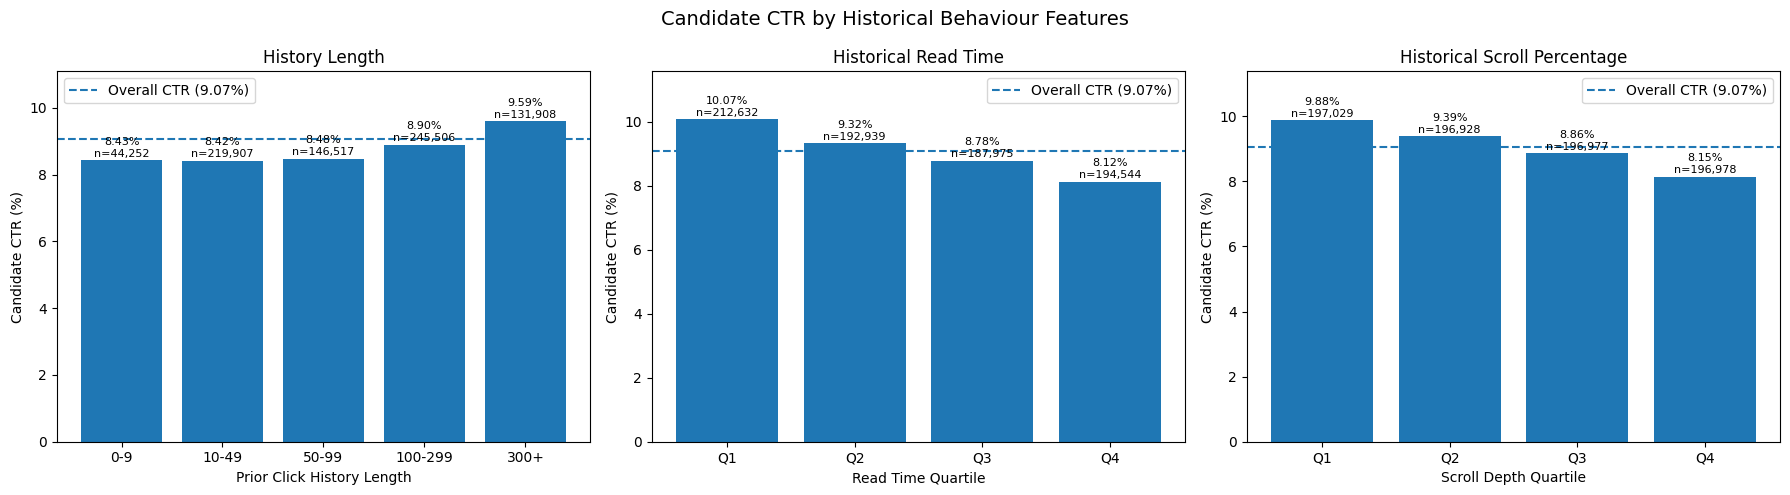

In [6]:
import matplotlib.pyplot as plt

overall_ctr = (
    user_analysis["clicks"].sum()
    / user_analysis["exposures"].sum()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

plot_info = [
    (
        history_ctr,
        "history_length_group",
        "History Length",
        "Prior Click History Length"
    ),
    (
        read_ctr,
        "read_time_group",
        "Historical Read Time",
        "Read Time Quartile"
    ),
    (
        scroll_ctr,
        "scroll_group",
        "Historical Scroll Percentage",
        "Scroll Depth Quartile"
    )
]

for ax, (
    df,
    group_col,
    title,
    xlabel
) in zip(
    axes,
    plot_info
):
    bars = ax.bar(
        df[group_col].astype(str),
        df["candidate_ctr"] * 100
    )

    # Overall CTR reference line
    ax.axhline(
        overall_ctr * 100,
        linestyle="--",
        label=(
            f"Overall CTR "
            f"({overall_ctr * 100:.2f}%)"
        )
    )

    # Add CTR + number of users
    for bar, (_, row) in zip(
        bars,
        df.iterrows()
    ):
        height = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            height + 0.05,
            (
                f"{row['candidate_ctr'] * 100:.2f}%\n"
                f"n={row['users']:,}"
            ),
            ha="center",
            va="bottom",
            fontsize=8
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Candidate CTR (%)")
    ax.legend()

    ax.set_ylim(
        0,
        df["candidate_ctr"].max() * 100 + 1.5
    )

plt.suptitle(
    "Candidate CTR by Historical Behaviour Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

Findings
1. Greater history length have higher CTR
2. Higher CTR for those with lesser read time and scroll percentage.


## Analysis on Current Features - Article Related
- Analyse History length from `category`, `article_type`, `article_type`, `premium`
- These describe the situation in which the recommendation was shown.

In [4]:
for col in [
    "category",
    "subcategory",
    "article_type",
    "topics",
    "premium"
]:
    print(
        col,
        type(
            df_articles[col]
            .dropna()
            .iloc[0]
        )
    )

category <class 'numpy.int16'>
subcategory <class 'numpy.ndarray'>
article_type <class 'str'>
topics <class 'numpy.ndarray'>
premium <class 'numpy.bool'>


In [5]:
import numpy as np
import pandas as pd

# =========================================
# 1. Scalar article features
# =========================================

scalar_cols = [
    "category",
    "article_type",
    "premium"
]

for col in scalar_cols:
    print(f"\n===== {col} =====")

    print(
        f"Missing: "
        f"{df_articles[col].isna().mean() * 100:.2f}%"
    )

    print(
        "Unique values:",
        df_articles[col].nunique()
    )

    print("\nDistribution:")
    print(
        df_articles[col]
        .value_counts(
            dropna=False,
            normalize=True
        )
        .mul(100)
        .head(20)
    )


# =========================================
# 2. Multi-value article features
# =========================================

multi_cols = [
    "subcategory",
    "topics"
]

for col in multi_cols:
    print(f"\n===== {col} =====")

    # Number of values assigned to each article
    value_count = (
        df_articles[col]
        .apply(
            lambda x:
            len(x)
            if isinstance(x, np.ndarray)
            else 0
        )
    )

    print(
        "Mean values per article:",
        round(value_count.mean(), 2)
    )

    print(
        "Median values per article:",
        value_count.median()
    )

    print(
        "Articles with no values:",
        f"{(value_count == 0).mean() * 100:.2f}%"
    )

    # Explode arrays into individual values
    exploded = (
        df_articles[col]
        .explode()
        .dropna()
    )

    print(
        "Unique values:",
        exploded.nunique()
    )

    print("\nMost common values:")
    print(
        exploded
        .value_counts()
        .head(20)
    )


===== category =====
Missing: 0.00%
Unique values: 32

Distribution:
category
118     22.207884
414     19.841327
140     17.985359
142     14.948901
572      3.686445
457      3.447479
565      3.210107
498      2.900248
2889     2.798289
512      2.678806
539      1.908540
529      1.564429
68       1.092074
2077     0.462000
1505     0.419783
2        0.203121
561      0.198342
2341     0.136210
2975     0.097179
2731     0.090807
Name: proportion, dtype: float64

===== article_type =====
Missing: 0.00%
Unique values: 16

Distribution:
article_type
article_default                  91.803475
article_video_standalone          3.124876
article_page_nine_girl            2.854048
article_scribblelive              0.695390
article_opinionen                 0.455628
article_standard_feature          0.418987
article_questions_and_answers     0.199935
article_native                    0.195155
article_fullscreen_gallery        0.124262
article_webtv                     0.083638
article_fea

In [6]:
import pandas as pd
import gc

# Smaller = safer for RAM
chunk_size = 200_000

category_parts = []
article_type_parts = []
premium_parts = []


for start in range(
    0,
    len(df_behaviors_train),
    chunk_size
):
    end = min(
        start + chunk_size,
        len(df_behaviors_train)
    )

    # Only keep columns we actually need
    chunk = (
        df_behaviors_train
        .iloc[start:end][
            [
                "article_ids_inview",
                "article_ids_clicked"
            ]
        ]
        .copy()
    )

    # Convert clicked list to set
    # for faster membership checking
    chunk["clicked_set"] = (
        chunk["article_ids_clicked"]
        .apply(set)
    )

    # One row per candidate article
    chunk = (
        chunk
        .explode("article_ids_inview")
        .rename(
            columns={
                "article_ids_inview":
                "article_id"
            }
        )
    )

    # Candidate click label
    chunk["clicked"] = [
        int(article_id in clicked_set)
        for article_id, clicked_set
        in zip(
            chunk["article_id"],
            chunk["clicked_set"]
        )
    ]

    # Remove large columns ASAP
    chunk = chunk.drop(
        columns=[
            "article_ids_clicked",
            "clicked_set"
        ]
    )

    # Add article features
    chunk = chunk.merge(
        df_articles[
            [
                "article_id",
                "category",
                "article_type",
                "premium"
            ]
        ],
        on="article_id",
        how="left"
    )

    # -------------------------
    # Category
    # -------------------------
    category_chunk = (
        chunk.groupby(
            "category",
            dropna=False
        )
        .agg(
            exposures=(
                "clicked",
                "size"
            ),
            clicks=(
                "clicked",
                "sum"
            )
        )
        .reset_index()
    )

    category_parts.append(
        category_chunk
    )

    # -------------------------
    # Article type
    # -------------------------
    article_type_chunk = (
        chunk.groupby(
            "article_type",
            dropna=False
        )
        .agg(
            exposures=(
                "clicked",
                "size"
            ),
            clicks=(
                "clicked",
                "sum"
            )
        )
        .reset_index()
    )

    article_type_parts.append(
        article_type_chunk
    )

    # -------------------------
    # Premium
    # -------------------------
    premium_chunk = (
        chunk.groupby(
            "premium",
            dropna=False
        )
        .agg(
            exposures=(
                "clicked",
                "size"
            ),
            clicks=(
                "clicked",
                "sum"
            )
        )
        .reset_index()
    )

    premium_parts.append(
        premium_chunk
    )

    # Clear current chunk from memory
    del chunk
    gc.collect()

    print(
        f"Processed "
        f"{end:,} / "
        f"{len(df_behaviors_train):,}"
    )


# =========================================
# Combine chunk results
# =========================================

def combine_results(
    parts,
    feature
):
    result = (
        pd.concat(
            parts,
            ignore_index=True
        )
        .groupby(
            feature,
            dropna=False,
            as_index=False
        )[
            [
                "exposures",
                "clicks"
            ]
        ]
        .sum()
    )

    result["candidate_ctr"] = (
        result["clicks"]
        / result["exposures"]
    )

    result["exposure_share_pct"] = (
        result["exposures"]
        / result["exposures"].sum()
        * 100
    )

    return result.sort_values(
        "exposures",
        ascending=False
    )


category_ctr = combine_results(
    category_parts,
    "category"
)

article_type_ctr = combine_results(
    article_type_parts,
    "article_type"
)

premium_ctr = combine_results(
    premium_parts,
    "premium"
)


# =========================================
# Results
# =========================================

print("\n===== CATEGORY CTR =====")
print(category_ctr)

print("\n===== ARTICLE TYPE CTR =====")
print(article_type_ctr)

print("\n===== PREMIUM CTR =====")
print(premium_ctr)

Processed 200,000 / 12,063,890
Processed 400,000 / 12,063,890
Processed 600,000 / 12,063,890
Processed 800,000 / 12,063,890
Processed 1,000,000 / 12,063,890
Processed 1,200,000 / 12,063,890
Processed 1,400,000 / 12,063,890
Processed 1,600,000 / 12,063,890
Processed 1,800,000 / 12,063,890
Processed 2,000,000 / 12,063,890
Processed 2,200,000 / 12,063,890
Processed 2,400,000 / 12,063,890
Processed 2,600,000 / 12,063,890
Processed 2,800,000 / 12,063,890
Processed 3,000,000 / 12,063,890
Processed 3,200,000 / 12,063,890
Processed 3,400,000 / 12,063,890
Processed 3,600,000 / 12,063,890
Processed 3,800,000 / 12,063,890
Processed 4,000,000 / 12,063,890
Processed 4,200,000 / 12,063,890
Processed 4,400,000 / 12,063,890
Processed 4,600,000 / 12,063,890
Processed 4,800,000 / 12,063,890
Processed 5,000,000 / 12,063,890
Processed 5,200,000 / 12,063,890
Processed 5,400,000 / 12,063,890
Processed 5,600,000 / 12,063,890
Processed 5,800,000 / 12,063,890
Processed 6,000,000 / 12,063,890
Processed 6,200,00

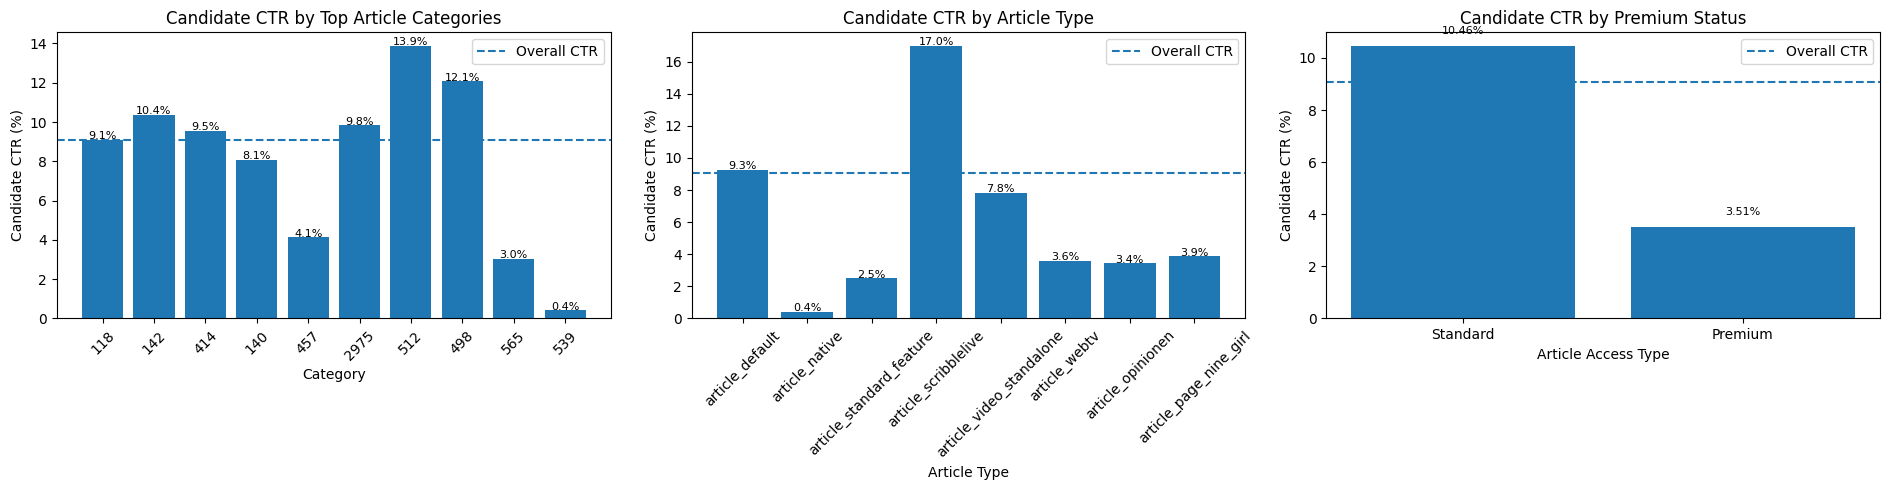

In [10]:
import matplotlib.pyplot as plt

overall_ctr = (
    df_behaviors_train["article_ids_clicked"].apply(len).sum()
    / df_behaviors_train["article_ids_inview"].apply(len).sum()
)

# Keep only the most exposed categories for readability
top_categories = (
    category_ctr
    .head(10)
    .copy()
)

# Keep article types with meaningful exposure
top_article_types = (
    article_type_ctr
    .head(8)
    .copy()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5)
)

# =========================
# Category
# =========================
bars = axes[0].bar(
    top_categories["category"].astype(str),
    top_categories["candidate_ctr"] * 100
)

axes[0].axhline(
    overall_ctr * 100,
    linestyle="--",
    label="Overall CTR"
)

axes[0].set_title(
    "Candidate CTR by Top Article Categories"
)

axes[0].set_xlabel("Category")
axes[0].set_ylabel("Candidate CTR (%)")
axes[0].tick_params(
    axis="x",
    rotation=45
)

for bar, (_, row) in zip(
    bars,
    top_categories.iterrows()
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{row['candidate_ctr'] * 100:.1f}%",
        ha="center",
        fontsize=8
    )

axes[0].legend()


# =========================
# Article type
# =========================
bars = axes[1].bar(
    top_article_types["article_type"],
    top_article_types["candidate_ctr"] * 100
)

axes[1].axhline(
    overall_ctr * 100,
    linestyle="--",
    label="Overall CTR"
)

axes[1].set_title(
    "Candidate CTR by Article Type"
)

axes[1].set_xlabel("Article Type")
axes[1].set_ylabel("Candidate CTR (%)")

axes[1].tick_params(
    axis="x",
    rotation=45
)

for bar, (_, row) in zip(
    bars,
    top_article_types.iterrows()
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{row['candidate_ctr'] * 100:.1f}%",
        ha="center",
        fontsize=8
    )

axes[1].legend()


# =========================
# Premium
# =========================
premium_plot = premium_ctr.copy()

premium_plot["label"] = (
    premium_plot["premium"]
    .map({
        False: "Standard",
        True: "Premium"
    })
)

bars = axes[2].bar(
    premium_plot["label"],
    premium_plot["candidate_ctr"] * 100
)

axes[2].axhline(
    overall_ctr * 100,
    linestyle="--",
    label="Overall CTR"
)

axes[2].set_title(
    "Candidate CTR by Premium Status"
)

axes[2].set_xlabel("Article Access Type")
axes[2].set_ylabel("Candidate CTR (%)")

for bar, (_, row) in zip(
    bars,
    premium_plot.iterrows()
):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        (
            f"{row['candidate_ctr'] * 100:.2f}%\n"
        ),
        ha="center",
        fontsize=8
    )

axes[2].legend()

plt.tight_layout()
plt.show()